# Crop-Pattern Comparison — All Six Runs (js_plot protocol)

Evaluates every thermal-crop sampling configuration on **Heydar-1746 (1536)** against the same
ground truth, using the exact js_plot metric protocol:

| Item | Rule |
|---|---|
| UE scaling | `ue_sat = ue * UE_SCALE` (stored value is already in the 256-resized frame, so UE_SCALE = 1) |
| Accept (positive) | `ue_sat < UE1_THRESH` (256-frame units; 4 ≈ 24 satellite px) |
| Correct (true) | `CE <= CE_THRESH` (satellite-frame px, inclusive) |
| CE | `||pred_center - gt_center||` |
| MACE | mean over 4 corners of `||pred_corner - gt_corner||` |

Runs covered:

| Key | Crops | Pattern | File |
|---|---|---|---|
| `5-random` | 5 (1 full + 4 shifted) | random | `thcrop_4r-google-1536_regen.xlsx` |
| `5-grid` | 5 | 2x2 grid | `thcrop_4g-google-1536_v2.xlsx` |
| `5-plus` | 5 | 4 cardinal (+) | `thcrop_4p-google-1536_v2.xlsx` |
| `5-cross` | 5 | 4 diagonal (x) | `thcrop_4x-google-1536_v2.xlsx` |
| `9-random` | 9 | random | `thcrop_8r-google-1536_v2.xlsx` |
| `9-star` | 9 | 4+ + 4x | `thcrop_8px-google-1536_v2.xlsx` |

Alignment with GT is positional (`iloc`, same as js_plot) and is asserted below.

In [1]:
# ==============================================================================
# CONFIG
# ==============================================================================
import numpy as np
import pandas as pd

GT_EXCEL = "js_datasets/Heydar-1746/gt-1536.xlsx"

RUNS = {
    "5-random": "js_datasets/Heydar-1746/thcrop_4r-google-1536_regen.xlsx",
    "5-grid":   "js_datasets/Heydar-1746/thcrop_4g-google-1536_v2.xlsx",
    "5-plus":   "js_datasets/Heydar-1746/thcrop_4p-google-1536_v2.xlsx",
    "5-cross":  "js_datasets/Heydar-1746/thcrop_4x-google-1536_v2.xlsx",
    "9-random": "js_datasets/Heydar-1746/thcrop_8r-google-1536_v2.xlsx",
    "9-star":   "js_datasets/Heydar-1746/thcrop_8px-google-1536_v2.xlsx",
}

# js_plot protocol constants
UE_SCALE    = 1      # stored UE is raw (256-resized frame) -> keep 1
UE1_THRESH  = 4.0    # accept if ue < 4 in the 256 frame (= 24 satellite px)
CE_THRESH   = 100.0  # satellite-frame px; correct (true) if CE <= CE_THRESH

CORNER_COLS = ["x1", "y1", "x2", "y2", "x3", "y3", "x4", "y4"]

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 60)

In [2]:
# ==============================================================================
# LOAD + ALIGN + COMPUTE (vectorised, identical semantics to js_plot)
# ==============================================================================
gt_df = pd.read_excel(GT_EXCEL)
G = gt_df[CORNER_COLS].to_numpy(float).reshape(-1, 4, 2)
gt_centers = G.mean(axis=1)

def load_run(path):
    df = pd.read_excel(path)
    # positional alignment with GT, exactly like js_plot's gt_df.iloc[idx]
    assert len(df) == len(gt_df), f"{path}: {len(df)} rows vs GT {len(gt_df)}"
    assert (df["img_idx"].to_numpy() == gt_df["img_idx"].to_numpy()).all(), f"{path}: img_idx order mismatch"
    P = df[CORNER_COLS].to_numpy(float).reshape(-1, 4, 2)
    ce   = np.linalg.norm(P.mean(axis=1) - gt_centers, axis=1)     # center error
    mace = np.linalg.norm(P - G, axis=2).mean(axis=1)              # mean corner error
    ue_sat = df["ue"].to_numpy(float) * UE_SCALE
    return df, dict(ce=ce, mace=mace, ue_sat=ue_sat)

def cm_metrics(acc_pred, acc_real):
    tp = int(np.sum( acc_pred &  acc_real))
    tn = int(np.sum(~acc_pred & ~acc_real))
    fp = int(np.sum( acc_pred & ~acc_real))
    fn = int(np.sum(~acc_pred &  acc_real))
    total = tp + tn + fp + fn
    accuracy      = (tp + tn) / total * 100 if total > 0 else 0.0
    pos_precision = tp / (tp + fp) * 100 if (tp + fp) > 0 else 0.0
    pos_recall    = tp / (tp + fn) * 100 if (tp + fn) > 0 else 0.0
    neg_precision = tn / (tn + fn) * 100 if (tn + fn) > 0 else 0.0
    neg_recall    = tn / (tn + fp) * 100 if (tn + fp) > 0 else 0.0
    f1_pos = 2*pos_precision*pos_recall/(pos_precision+pos_recall) if (pos_precision+pos_recall) > 0 else 0.0
    f1_neg = 2*neg_precision*neg_recall/(neg_precision+neg_recall) if (neg_precision+neg_recall) > 0 else 0.0
    return dict(tp=tp, tn=tn, fp=fp, fn=fn, total=total,
                accuracy=accuracy,
                pos_precision=pos_precision, pos_recall=pos_recall, f1_pos=f1_pos,
                neg_precision=neg_precision, neg_recall=neg_recall, f1_neg=f1_neg)

data = {}
for name, path in RUNS.items():
    df, arrs = load_run(path)
    acc_pred = arrs["ue_sat"] < UE1_THRESH          # accepted (positive)
    acc_real = arrs["ce"] <= CE_THRESH              # correct (true)
    data[name] = dict(df=df, **arrs,
                      acc_pred=acc_pred, acc_real=acc_real,
                      cm=cm_metrics(acc_pred, acc_real))
    print(f"loaded {name:10s}  n={len(df)}  accept={acc_pred.mean()*100:6.2f}%  correct={acc_real.mean()*100:6.2f}%")
print("\nAll runs aligned with GT (positional, 1782/1782).")

loaded 5-random    n=1782  accept= 80.53%  correct= 93.10%


loaded 5-grid      n=1782  accept= 70.71%  correct= 93.04%


loaded 5-plus      n=1782  accept= 82.94%  correct= 93.04%


loaded 5-cross     n=1782  accept= 79.52%  correct= 93.10%


loaded 9-random    n=1782  accept= 80.81%  correct= 93.04%


loaded 9-star      n=1782  accept= 81.48%  correct= 93.04%

All runs aligned with GT (positional, 1782/1782).


In [3]:
# ==============================================================================
# PER-RUN DISTANCE REPORT + CONFUSION MATRIX (js_plot format)
# ==============================================================================
for name, d in data.items():
    ue, ce, mace = d["ue_sat"], d["ce"], d["mace"]
    acc = d["acc_pred"]
    cm  = d["cm"]
    n = len(ce)
    print("=" * 110)
    print(f"RUN: {name}   ({RUNS[name]})")
    print("=" * 110)
    print(f"UE (satellite frame):  mean={ue.mean():8.2f}  median={np.median(ue):8.2f}  "
          f"std={ue.std():7.2f}  min={ue.min():6.2f}  max={ue.max():7.2f}")
    print(f"Thresholds: UE1 < {UE1_THRESH} px  |  CE <= {CE_THRESH} px")
    print("-" * 110)
    print(f"{'Method':<12}{'Subset':<12}{'Count':>7}{'MACE Avg':>11}{'MACE Std':>11}"
          f"{'CE Avg':>9}{'CE Std':>9}{'CE Max':>9}{'CE<=T':>7}{'CE>T':>7}")
    for subset, mask in [("All", np.ones(n, bool)), ("Accepted", acc), ("Rejected", ~acc)]:
        c, m = ce[mask], mace[mask]
        ok = int(np.sum(c <= CE_THRESH))
        print(f"{'STHN':<12}{subset:<12}{len(c):>7}{m.mean():>11.2f}{m.std():>11.2f}"
              f"{c.mean():>9.2f}{c.std():>9.2f}{c.max():>9.2f}{ok:>7}{len(c)-ok:>7}")
    print("-" * 110)
    print(f"CONFUSION (positive = accepted):  TP={cm['tp']}  FP={cm['fp']}  TN={cm['tn']}  FN={cm['fn']}   (total {cm['total']})")
    print(f"  Accuracy={cm['accuracy']:.2f}%   Precision(+)={cm['pos_precision']:.2f}%   "
          f"Recall(+)={cm['pos_recall']:.2f}%   F1(+)={cm['f1_pos']:.2f}%")
    print(f"  Precision(-)={cm['neg_precision']:.2f}%   Recall(-)={cm['neg_recall']:.2f}%   F1(-)={cm['f1_neg']:.2f}%")
    print()

RUN: 5-random   (js_datasets/Heydar-1746/thcrop_4r-google-1536_regen.xlsx)
UE (satellite frame):  mean=    5.04  median=    2.99  std=   5.54  min=  1.82  max=  47.64
Thresholds: UE1 < 4.0 px  |  CE <= 100.0 px
--------------------------------------------------------------------------------------------------------------
Method      Subset        Count   MACE Avg   MACE Std   CE Avg   CE Std   CE Max  CE<=T   CE>T
STHN        All            1782      35.61     117.13    33.14   116.90  1030.34   1659    123
STHN        Accepted       1435       7.14      14.08     5.08    13.64   376.66   1431      4
STHN        Rejected        347     153.31     228.97   149.18   229.54  1030.34    228    119
--------------------------------------------------------------------------------------------------------------
CONFUSION (positive = accepted):  TP=1431  FP=4  TN=119  FN=228   (total 1782)
  Accuracy=86.98%   Precision(+)=99.72%   Recall(+)=86.26%   F1(+)=92.50%
  Precision(-)=34.29%   Recall(-)=

In [4]:
# ==============================================================================
# COMPARISON SUMMARY (all six runs)
# ==============================================================================
rows = []
for name, d in data.items():
    ue, ce, mace, acc, cm = d["ue_sat"], d["ce"], d["mace"], d["acc_pred"], d["cm"]
    rows.append({
        "run": name,
        "n": len(ce),
        "ue_mean": ue.mean(), "ue_median": np.median(ue),
        "accept_rate%": acc.mean() * 100,
        "correct_rate%": d["acc_real"].mean() * 100,
        "mace_mean": mace.mean(),
        "mace_acc": mace[acc].mean(), "mace_rej": mace[~acc].mean(),
        "ce_median": np.median(ce), "ce_acc": ce[acc].mean(),
        "tp": cm["tp"], "fp": cm["fp"], "tn": cm["tn"], "fn": cm["fn"],
        "accuracy%": cm["accuracy"], "precision%": cm["pos_precision"],
        "recall%": cm["pos_recall"], "f1%": cm["f1_pos"],
    })
summary = pd.DataFrame(rows).set_index("run")
summary.to_csv("reports/crop_pattern_summary.csv", encoding="utf-8-sig")
print("Saved: reports/crop_pattern_summary.csv\n")
print(summary[["ue_mean", "ue_median", "accept_rate%", "correct_rate%",
               "mace_mean", "mace_acc", "mace_rej", "ce_median"]].round(2).to_string())
print()
print(summary[["tp", "fp", "tn", "fn", "accuracy%", "precision%", "recall%", "f1%"]].round(2).to_string())

Saved: reports/crop_pattern_summary.csv

          ue_mean  ue_median  accept_rate%  correct_rate%  mace_mean  mace_acc  mace_rej  ce_median
run                                                                                                
5-random     5.04       2.99         80.53          93.10      35.61      7.14    153.31       4.47
5-grid       6.79       3.14         70.71          93.04      35.62      6.35    106.27       4.48
5-plus       4.76       2.98         82.94          93.04      35.61      7.58    171.92       4.47
5-cross      5.39       3.01         79.52          93.10      35.59      6.79    147.40       4.47
9-random     4.65       2.32         80.81          93.04      35.60      7.02    155.98       4.47
9-star       4.57       2.31         81.48          93.04      35.58      7.00    161.31       4.47

            tp  fp   tn   fn  accuracy%  precision%  recall%    f1%
run                                                                
5-random  1431   4  11

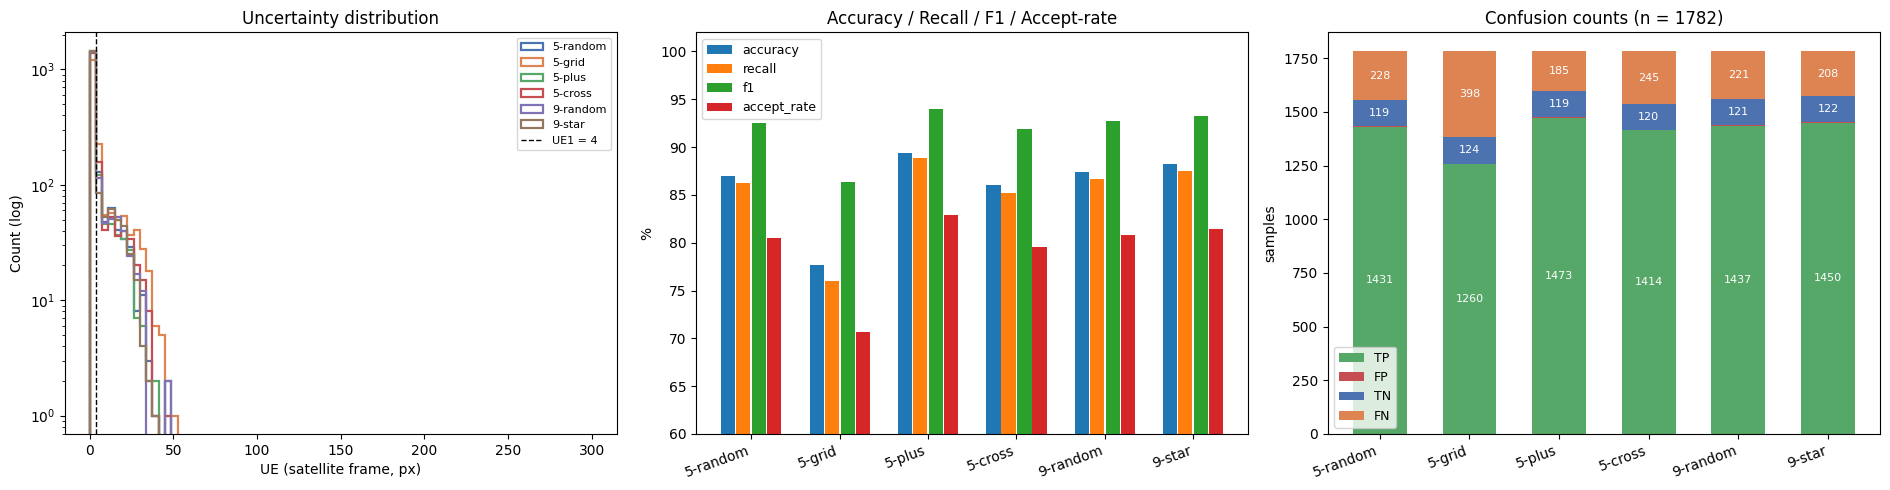

Saved: reports/assets/crop_pattern_comparison.png


In [5]:
# ==============================================================================
# PLOTS
# ==============================================================================
import matplotlib.pyplot as plt

order = list(RUNS.keys())
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# (1) UE distribution (satellite frame) — log y
for name, c in zip(order, colors):
    axes[0].hist(data[name]["ue_sat"], bins=80, range=(0, 300), histtype="step",
                 linewidth=1.6, label=name, color=c)
axes[0].axvline(UE1_THRESH, color="k", linestyle="--", linewidth=1, label=f"UE1 = {UE1_THRESH:.0f}")
axes[0].set_yscale("log")
axes[0].set_xlabel("UE (satellite frame, px)")
axes[0].set_ylabel("Count (log)")
axes[0].set_title("Uncertainty distribution")
axes[0].legend(fontsize=8)

# (2) confusion-matrix metrics
x = np.arange(len(order))
for metric, off in [("accuracy%", -0.26), ("recall%", -0.09), ("f1%", 0.09), ("accept_rate%", 0.26)]:
    axes[1].bar(x + off, summary.loc[order, metric], width=0.16, label=metric.replace("%", ""))
axes[1].set_xticks(x); axes[1].set_xticklabels(order, rotation=20, ha="right")
axes[1].set_ylim(60, 102)
axes[1].set_ylabel("%")
axes[1].set_title("Accuracy / Recall / F1 / Accept-rate")
axes[1].legend(fontsize=9)

# (3) TP / FP / TN / FN
bot = np.zeros(len(order))
for key, lab, c in [("tp", "TP", "#55A868"), ("fp", "FP", "#C44E52"),
                    ("tn", "TN", "#4C72B0"), ("fn", "FN", "#DD8452")]:
    vals = summary.loc[order, key].to_numpy(float)
    axes[2].bar(x, vals, bottom=bot, label=lab, color=c, width=0.6)
    for xi, (v, b) in enumerate(zip(vals, bot)):
        if v > 60:
            axes[2].text(xi, b + v / 2, f"{int(v)}", ha="center", va="center", fontsize=8, color="w")
    bot += vals
axes[2].set_xticks(x); axes[2].set_xticklabels(order, rotation=20, ha="right")
axes[2].set_ylabel("samples")
axes[2].set_title("Confusion counts (n = 1782)")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.savefig("reports/assets/crop_pattern_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: reports/assets/crop_pattern_comparison.png")

In [6]:
# ==============================================================================
# THRESHOLD SWEEP — balance FP vs FN
# For each candidate UE1 threshold t (satellite frame): accepted = ue_sat < t.
# Raising t converts FN into TP but also TN into FP, so FP rises and FN falls.
# Balance point = t where FP == FN.  Also reported: t minimizing FP+FN (= max accuracy).
# ==============================================================================
thresholds = np.arange(5.0, 200.5, 0.5)

def sweep(ue_sat, acc_real, ts):
    fp = np.array([np.sum((ue_sat < t) & ~acc_real) for t in ts], dtype=int)
    fn = np.array([np.sum((ue_sat >= t) & acc_real) for t in ts], dtype=int)
    return fp, fn

def balance_threshold(ts, fp, fn):
    d = fp - fn                       # <0 at small t, >0 at large t
    idx = np.where(d >= 0)[0]
    if len(idx) == 0:
        return None
    i = idx[0]
    if i == 0:
        return float(ts[0])
    t0, t1, d0, d1 = ts[i-1], ts[i], d[i-1], d[i]
    return float(t0 - d0 * (t1 - t0) / (d1 - d0))   # linear interpolation of FP-FN = 0

sweeps, rows = {}, []
for name, d in data.items():
    fp, fn = sweep(d["ue_sat"], d["acc_real"], thresholds)
    sweeps[name] = (fp, fn)
    t_bal = balance_threshold(thresholds, fp, fn)
    cm_bal = cm_metrics(d["ue_sat"] < t_bal, d["acc_real"]) if t_bal else None
    err = fp + fn
    i_min = int(err.argmin())
    t_err = thresholds[i_min]
    cm_err = cm_metrics(d["ue_sat"] < t_err, d["acc_real"])
    cm30 = d["cm"]
    rows.append({
        "run": name,
        "FP@30": cm30["fp"], "FN@30": cm30["fn"], "|FP-FN|@30": abs(cm30["fp"] - cm30["fn"]),
        "t_balance": t_bal, "FP=FN": cm_bal["fp"] if cm_bal else None,
        "acc@bal": cm_bal["accuracy"] if cm_bal else None, "F1@bal": cm_bal["f1_pos"] if cm_bal else None,
        "t_minerr": t_err, "FP+FN@minerr": int(err[i_min]),
        "acc@minerr": cm_err["accuracy"],
    })

sweep_df = pd.DataFrame(rows).set_index("run")
print(f"thresholds swept: {thresholds[0]:.0f} .. {thresholds[-1]:.0f} px (satellite frame), step {thresholds[1]-thresholds[0]:.1f}")
print("t_balance: threshold where FP == FN (accepted-vs-rejected errors balanced)")
print("t_minerr : threshold minimizing FP+FN (= maximizing accuracy; upper end means 'accept almost all')\n")
print(sweep_df.round(2).to_string())

thresholds swept: 5 .. 200 px (satellite frame), step 0.5
t_balance: threshold where FP == FN (accepted-vs-rejected errors balanced)
t_minerr : threshold minimizing FP+FN (= maximizing accuracy; upper end means 'accept almost all')

          FP@30  FN@30  |FP-FN|@30  t_balance  FP=FN  acc@bal  F1@bal  t_minerr  FP+FN@minerr  acc@minerr
run                                                                                                      
5-random      4    228         224      15.33     64    92.76   96.11      19.5           111       93.77
5-grid        0    398         398      24.00     64    92.82   96.14      30.5           122       93.15
5-plus        5    185         180      14.38     67    92.42   95.93      21.0           115       93.55
5-cross       3    245         242      18.50     55    93.83   96.68      21.5           100       94.39
9-random      3    221         218      16.41     62    93.10   96.29      20.5           113       93.66
9-star        2    208   

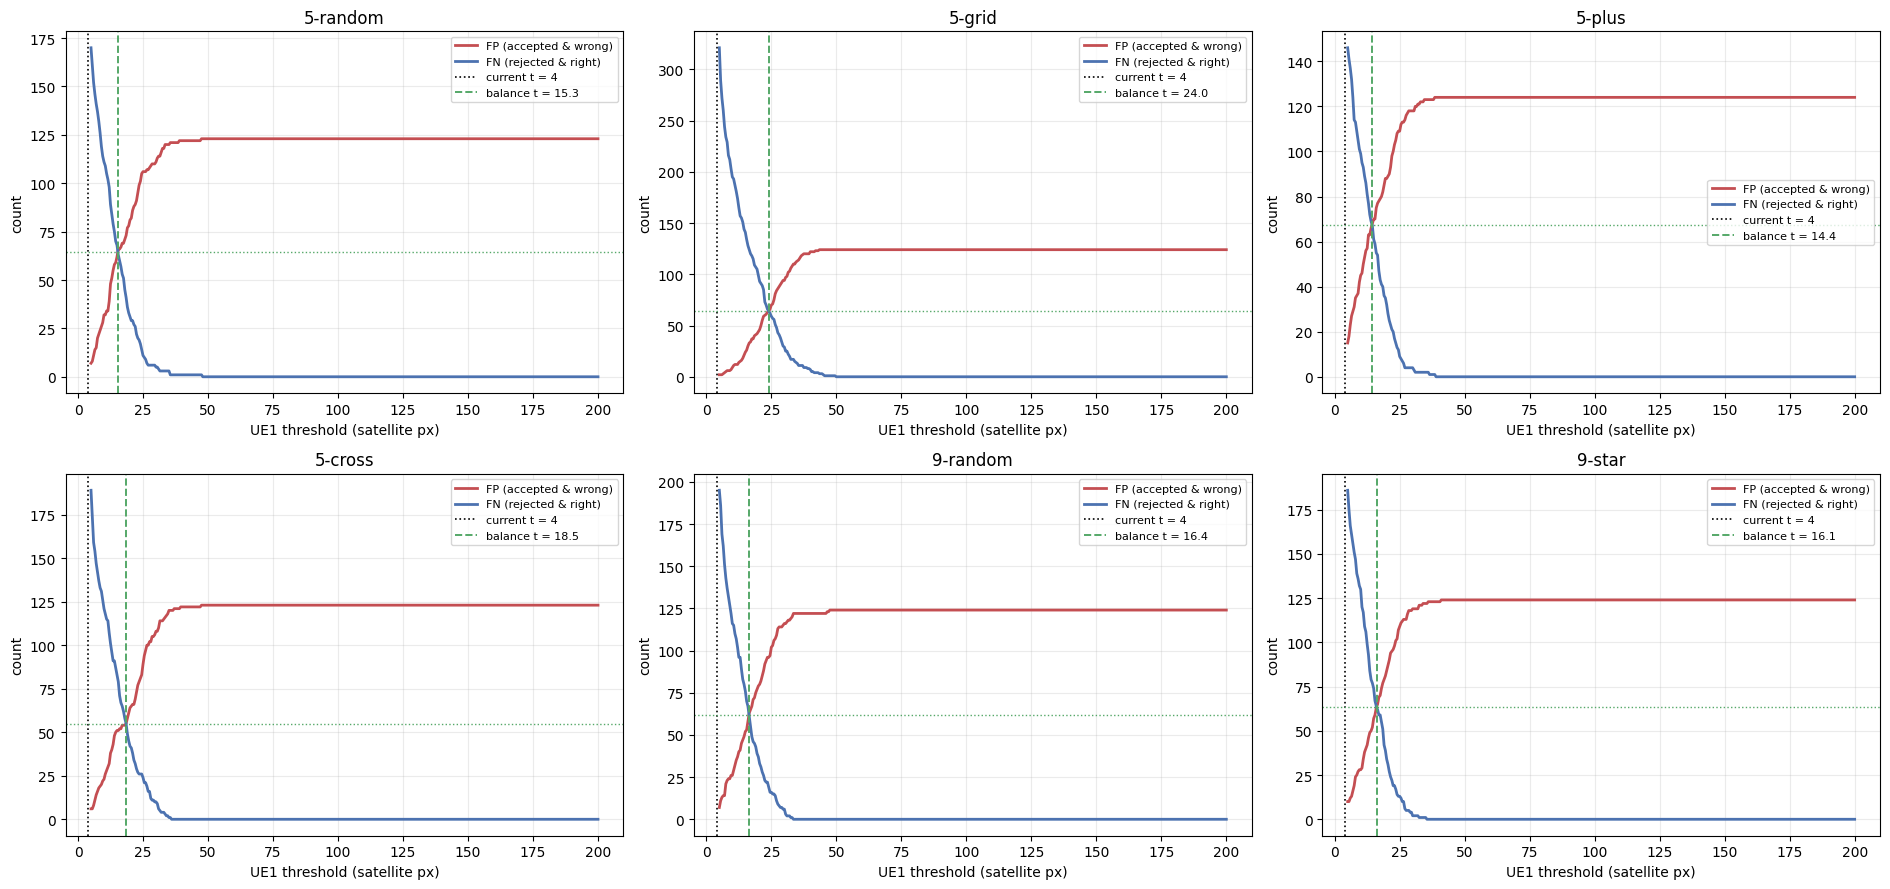

Saved: reports/assets/threshold_balance.png


In [7]:
# ==============================================================================
# PLOTS — FP & FN vs threshold, balance points marked
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(19, 9))

for ax, (name, d) in zip(axes.flat, data.items()):
    fp, fn = sweeps[name]
    t_bal = balance_threshold(thresholds, fp, fn)
    ax.plot(thresholds, fp, color="#C44E52", linewidth=2, label="FP (accepted & wrong)")
    ax.plot(thresholds, fn, color="#4C72B0", linewidth=2, label="FN (rejected & right)")
    ax.axvline(UE1_THRESH, color="k", linestyle=":", linewidth=1.2, label=f"current t = {UE1_THRESH:.0f}")
    if t_bal:
        ax.axvline(t_bal, color="#55A868", linestyle="--", linewidth=1.4,
                   label=f"balance t = {t_bal:.1f}")
        ax.axhline(np.interp(t_bal, thresholds, fp), color="#55A868", linestyle=":", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("UE1 threshold (satellite px)")
    ax.set_ylabel("count")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("reports/assets/threshold_balance.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: reports/assets/threshold_balance.png")